# 13주차 생성형 AI 콘텐츠 제작 — 강의자 시연용
    ## 오늘의 질문
    AI가 매력적인 문구를 쓰면 사실까지 정확할까? 어떤 프롬프트가 누락을 줄일까?
    **완성 결과:** 동일한 행사 데이터로 사람 초안·기본 AI·개선 AI 비교표, 최종 홍보 문구, 이미지 프롬프트 및 성찰 기록.
    CPU 사용, API 키 불필요. Colab에서 파일 → Drive에 사본 저장 후 순서대로 실행하세요.
    실제 생성은 ChatGPT 등 대화형 서비스에 프롬프트를 붙여 넣습니다. 노트북은 생성 모델 자체가 아니라 입력 자료와 비교 도구입니다.
    강의자 예시 문구는 시연용 가상 기준문 및 이 자료 제작 과정의 AI 예시문이며, 실제 학생/사람 작성 측정값이 아닙니다.

## 1. 데이터 읽기
4개의 가상 캠퍼스 행사, 행=행사 1건, 열=행사 사실. 자동 로딩 실패 시 내장 동일 데이터 사용. 직접 다운로드 후 Colab 파일 창에 event_briefs.csv 업로드 가능.

In [3]:
import csv, io, json, pathlib, re
from urllib.request import urlopen
from IPython.display import display, Markdown
import pandas as pd
import matplotlib.pyplot as plt
url = "https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/week13/event_briefs.csv"
local = pathlib.Path("event_briefs.csv")
if local.exists():
    raw = local.read_text(encoding="utf-8-sig")
else:
    try:
        with urlopen(url, timeout=8) as r:
            raw = r.read().decode("utf-8-sig")
    except Exception:
        raw = 'id,event,date,time,place,capacity,fee,deadline,audience,action\nA01,캠퍼스 북교환회,2026-12-03,14:00~16:00,학생회관 1층,40,무료,2026-12-01,재학생,도서 1권 지참 후 신청\nA02,디지털 사진 전시회,2026-12-04,13:00~17:00,도서관 로비,60,무료,2026-12-02,재학생,온라인 신청\nA03,텀블러 데이,2026-12-07,12:00~14:00,학생식당 앞,80,무료,2026-12-05,재학생,개인 텀블러 지참\nA04,진로 포트폴리오 특강,2026-12-08,15:00~17:00,강의동 201호,30,무료,2026-12-06,재학생,온라인 신청\n'
df = pd.read_csv(io.StringIO(raw), dtype=str)
assert len(df) == 4 and df["id"].is_unique
display(df)

    id        event        date  ...    deadline audience         action
0  A01     캠퍼스 북교환회  2026-12-03  ...  2026-12-01      재학생  도서 1권 지참 후 신청
1  A02   디지털 사진 전시회  2026-12-04  ...  2026-12-02      재학생         온라인 신청
2  A03       텀블러 데이  2026-12-07  ...  2026-12-05      재학생      개인 텀블러 지참
3  A04  진로 포트폴리오 특강  2026-12-08  ...  2026-12-06      재학생         온라인 신청

[4 rows x 10 columns]


id,event,date,time,place,capacity,fee,deadline,audience,action
A01,캠퍼스 북교환회,2026-12-03,14:00~16:00,학생회관 1층,40,무료,2026-12-01,재학생,도서 1권 지참 후 신청
A02,디지털 사진 전시회,2026-12-04,13:00~17:00,도서관 로비,60,무료,2026-12-02,재학생,온라인 신청
A03,텀블러 데이,2026-12-07,12:00~14:00,학생식당 앞,80,무료,2026-12-05,재학생,개인 텀블러 지참
A04,진로 포트폴리오 특강,2026-12-08,15:00~17:00,강의동 201호,30,무료,2026-12-06,재학생,온라인 신청


## 2. 행사 선택
A01~A04 중 1개를 선택하세요. 시연은 A01. 날짜·시간·정원 등은 반드시 원자료와 대조합니다.

In [5]:
event_id = "A01"
row = df.loc[df["id"] == event_id].iloc[0].to_dict()
facts = {k:v for k,v in row.items() if k != "id"}
print(json.dumps(facts, ensure_ascii=False, indent=2))

{
  "event": "캠퍼스 북교환회",
  "date": "2026-12-03",
  "time": "14:00~16:00",
  "place": "학생회관 1층",
  "capacity": "40",
  "fee": "무료",
  "deadline": "2026-12-01",
  "audience": "재학생",
  "action": "도서 1권 지참 후 신청"
}


## 3. 프롬프트 만들기
먼저 AI 없이 200자 이내 홍보문을 작성해 저장하세요. 그 뒤 기본/개선 프롬프트를 각각 새 대화에서 같은 모델로 실행합니다. 출력 및 사용 도구·날짜를 기록하세요.

In [7]:
basic_prompt = f"{row['event']} 홍보 문구를 작성해 줘."
improved_prompt = f"""역할: 대학 학생회 콘텐츠 담당자
목표: 재학생 대상 행사 홍보문 작성
근거 데이터: {json.dumps(facts, ensure_ascii=False)}
조건: 위 데이터만 사용. 날짜/시간/장소/정원/비용/마감/대상/신청행동을 정확히 포함.
없는 사실(경품, 혜택, 링크 등)은 추가 금지. 200자 이내.
출력: 제목과 본문, 신청 행동 문구."""
print("기본 프롬프트:", basic_prompt)
print("\n개선 프롬프트:", improved_prompt)

기본 프롬프트: 캠퍼스 북교환회 홍보 문구를 작성해 줘.

개선 프롬프트: 역할: 대학 학생회 콘텐츠 담당자
목표: 재학생 대상 행사 홍보문 작성
근거 데이터: {"event": "캠퍼스 북교환회", "date": "2026-12-03", "time": "14:00~16:00", "place": "학생회관 1층", "capacity": "40", "fee": "무료", "deadline": "2026-12-01", "audience": "재학생", "action": "도서 1권 지참 후 신청"}
조건: 위 데이터만 사용. 날짜/시간/장소/정원/비용/마감/대상/신청행동을 정확히 포함.
없는 사실(경품, 혜택, 링크 등)은 추가 금지. 200자 이내.
출력: 제목과 본문, 신청 행동 문구.


## 4. 세 문구 입력
학생은 아래 빈 따옴표에 직접 작성한 문구와 AI 응답을 붙여넣고 실행. 강의에서는 예시 문구로 코드 시연. AI 사용이 불가능하면 생성 결과 대신 시연용 예시로 분석만 하고 실제 생성 여부를 표시하세요.

In [9]:
drafts = {'사람 작성(시연용 가상 기준문)': '캠퍼스 북교환회에 참여하세요! 2026-12-03 14:00~16:00 학생회관 1층에서 재학생 40명을 모집합니다. 참가비 무료, 신청은 2026-12-01까지. 도서 1권 지참 후 신청하세요.', '기본 AI(예시 생성문)': '책을 사랑하는 여러분, 캠퍼스 북교환회로 초대합니다! 다양한 책을 만나고 친구들과 즐거운 시간을 보내세요. 지금 신청하세요!', '개선 AI(예시 생성문)': '캠퍼스 북교환회 | 재학생 여러분, 책을 바꿔 읽어 보세요! 2026-12-03 14:00~16:00, 학생회관 1층. 정원 40명, 참가비 무료. 2026-12-01까지 도서 1권 지참 후 신청하세요.'}
for k,v in drafts.items():
    print(k, ':', v or '(미작성)')

사람 작성(시연용 가상 기준문) : 캠퍼스 북교환회에 참여하세요! 2026-12-03 14:00~16:00 학생회관 1층에서 재학생 40명을 모집합니다. 참가비 무료, 신청은 2026-12-01까지. 도서 1권 지참 후 신청하세요.
기본 AI(예시 생성문) : 책을 사랑하는 여러분, 캠퍼스 북교환회로 초대합니다! 다양한 책을 만나고 친구들과 즐거운 시간을 보내세요. 지금 신청하세요!
개선 AI(예시 생성문) : 캠퍼스 북교환회 | 재학생 여러분, 책을 바꿔 읽어 보세요! 2026-12-03 14:00~16:00, 학생회관 1층. 정원 40명, 참가비 무료. 2026-12-01까지 도서 1권 지참 후 신청하세요.


## 5. 정확 일치 점검
9개 사실 문자열의 포함 여부를 0/1로 검사. 수치만 우연히 포함되거나 표현이 바뀌면 판정이 부정확할 수 있음. 문맥, 허위 추가, 가독성은 직접 검토합니다.

                   event  date  time  place  ...  audience  action  included  chars
사람 작성(시연용 가상 기준문)      1     1     1      1  ...         1       1         9    109
기본 AI(예시 생성문)          1     0     0      0  ...         0       0         1     69
개선 AI(예시 생성문)          1     1     1      1  ...         1       1         9    113

[3 rows x 11 columns]
                   event  date  time  place  capacity  fee  deadline  audience  action  included  chars
사람 작성(시연용 가상 기준문)      1     1     1      1         1    1         1         1       1         9    109
기본 AI(예시 생성문)          1     0     0      0         0    0         0         0       0         1     69
개선 AI(예시 생성문)          1     1     1      1         1    1         1         1       1         9    113


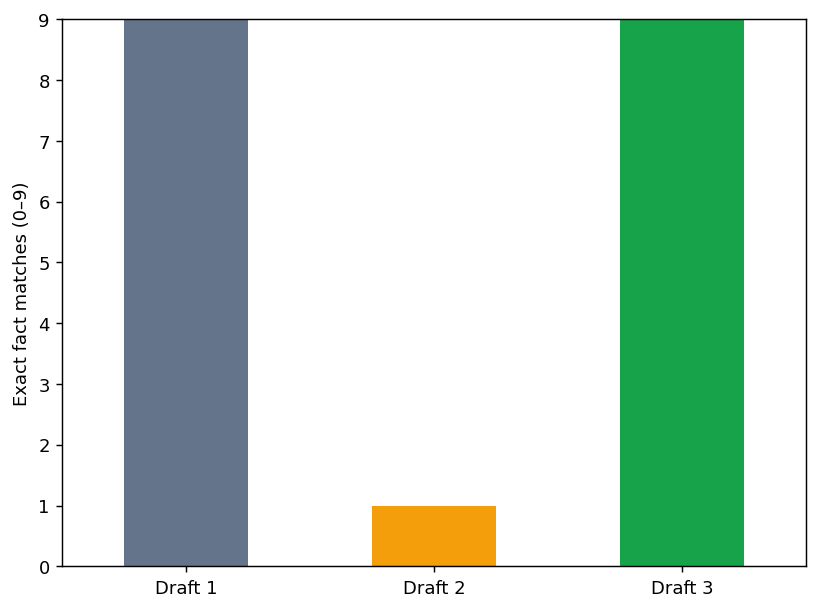

In [11]:
fields = ["event","date","time","place","capacity","fee","deadline","audience","action"]
def coverage(text):
    return {key: int(facts[key] in text) for key in fields}
valid = {k:v for k,v in drafts.items() if v.strip()}
if valid:
    checks = pd.DataFrame({k:coverage(v) for k,v in valid.items()}).T
    checks["included"] = checks.sum(axis=1)
    checks["chars"] = [len(valid[k]) for k in checks.index]
    display(checks)
    print(checks.to_string())
    ax = checks["included"].plot.bar(color=["#64748b","#f59e0b","#16a34a"][:len(checks)], ylim=(0,9))
    ax.set_xticklabels(["Draft "+str(i+1) for i in range(len(checks))], rotation=0)
    ax.set_ylabel("Exact fact matches (0–9)")
    plt.tight_layout()
    plt.show()
else:
    print("아직 작성한 문구가 없습니다. 4단계에서 입력하세요.")

## 6. 직접 평가 및 최종 콘텐츠
누락/허위 사실, 대상 적합성, 가독성, 행동 유도, 저작권·개인정보를 확인하고 수정하세요. 이미지 생성 서비스에는 실명·로고·개인사진 대신 가상 일러스트를 요청하고 날짜 등 핵심 문자는 직접 배치하세요.

In [13]:
manual_review = '기본 AI는 행사명만 정확히 포함. 개선 AI와 가상 기준문은 9개 사실을 포함했지만 표현과 문맥도 확인해야 함.'
reflection = '근거와 출력 조건이 누락을 줄이는 데 도움이 될 수 있다. 단 1회 예시로 일반화할 수 없다.'
ai_tool_record = '자료 제작 AI 예시 / 비교 시연용 고정 문구, 실제 학생 실험 아님'
final_text = '캠퍼스 북교환회 | 재학생 여러분, 책을 바꿔 읽어 보세요! 2026-12-03 14:00~16:00, 학생회관 1층. 정원 40명, 참가비 무료. 2026-12-01까지 도서 1권 지참 후 신청하세요.'
image_prompt = '대학 캠퍼스의 책 교환 행사, 따뜻한 일러스트, 책과 교환 화살표, 세로형 4:5, 하단에 문구 추가용 여백, 텍스트와 브랜드 로고 없음'

## 7. 저장 및 제출
실행 후 왼쪽 파일 창에서 week13_result.json을 다운로드. 학생은 사본 노트북(.ipynb), 결과 JSON, 이미지 또는 스케치와 출처/생성 기록을 제출합니다.

In [15]:
# 입력값을 채운 뒤 실행하여 제출 파일 만들기
result = {"event_id":event_id,"prompts":{"basic":basic_prompt,"improved":improved_prompt},
          "drafts":drafts,"manual_review":manual_review,"reflection":reflection,
          "ai_tool_record":ai_tool_record,"final":final_text,"image_prompt":image_prompt}
pathlib.Path("week13_result.json").write_text(json.dumps(result, ensure_ascii=False,indent=2),encoding="utf-8")
print("저장: week13_result.json")
if not all([all(v.strip() for v in drafts.values()), manual_review.strip(), reflection.strip(), final_text.strip(), ai_tool_record.strip(), image_prompt.strip()]):
    print("미완성 항목이 있습니다. 제출 전 모두 채우세요.")
else:
    print("기록 항목 입력 완료: 사실/저작권/가독성을 직접 확인하세요.")

저장: week13_result.json
기록 항목 입력 완료: 사실/저작권/가독성을 직접 확인하세요.
